# Skin Cancer Detection – Melanoma Classification using Deep Learning

### 1. Introduction:
Skin cancer is one of the most common cancers worldwide. Early identification is crucial for effective treatment.
In this project, we create a Deep Learning model using Convolutional Neural Networks (CNN) with Transfer Learning (EfficientNetB0) to classify skin lesion images into two categories:
- **Benign**: Non-cancerous lesions
- **Malignant**: Cancerous melanoma lesions

### 2. Project Objectives:
- Load and explore the skin lesion image dataset.
- Build an efficient data loading pipeline with TensorFlow / Keras.
- Implement Transfer Learning using pre-trained EfficientNetB0.
- Train and evaluate the model using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Visualize training history, Confusion Matrix, and ROC Curve.
- Save and reload the trained model for inference.


In [6]:
%pip install matplotlib scikit-learn tensorflow


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("All core libraries imported successfully!")

TensorFlow: 2.21.0
NumPy: 2.4.6
All core libraries imported successfully!


In [8]:
# Set random seeds for reproducible results
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
print(f"Random seed set to {SEED} & sklearn metrics imported.")

libraries imported successfully


In [9]:
import os
from pathlib import Path

# Search for the melanoma dataset in common locations
candidate_paths = [
    Path("melanoma_cancer_dataset"),
    Path("Skin Cancer Detection – Melanoma Classification/melanoma_cancer_dataset"),
    Path("/Users/budh/Desktop/Deep-Learning-/Skin Cancer Detection – Melanoma Classification/melanoma_cancer_dataset")
]

dataset_path = next((p for p in candidate_paths if p.exists() and p.is_dir()), None)

if dataset_path is None:
    raise FileNotFoundError("Could not find 'melanoma_cancer_dataset'. Please check the folder location.")

dataset_path = str(dataset_path.resolve())
print(f"Dataset path resolved to: {dataset_path}")
print("Directory contents:")
for item in sorted(os.listdir(dataset_path)):
    if not item.startswith('.'):
        print(f"  - {item}")

Files and folders in My Drive:
.DS_Store
test
train


In [10]:
# Checking folders and image counts in dataset
from pathlib import Path

# Included .png with leading dot
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

for split in ['train', 'test']:
    split_path = Path(dataset_path) / split
    print(f"\n--- {split.upper()} DATASET ---")
    if split_path.exists():
        for class_folder in sorted(split_path.iterdir()):
            if class_folder.is_dir():
                images = [
                    file for file in class_folder.rglob('*')
                    if file.is_file() and file.suffix.lower() in image_extensions
                ]
                print(f"{class_folder.name}: {len(images)} images")


---TRAIN DATASET---
benign : 5000 images
malignant : 4605 images

---TEST DATASET---
benign : 500 images
malignant : 500 images


In [15]:
import tensorflow as tf
from pathlib import Path

# Check common paths for existing saved model
candidate_model_paths = [
    Path("skin_lesion_practice_model.keras"),
    Path("../skin_lesion_practice_model.keras"),
    Path("Skin Cancer Detection – Melanoma Classification/skin_lesion_practice_model.keras"),
    Path("/Users/budh/Desktop/Deep-Learning-/skin_lesion_practice_model.keras")
]

model_path = next((p for p in candidate_model_paths if p.exists() and p.is_file()), None)

if model_path is not None:
    print(f"Found existing saved model at: {model_path.resolve()}")
    try:
        loaded_model = tf.keras.models.load_model(str(model_path.resolve()), compile=False)
        print("Model loaded successfully!")
        loaded_model.summary()
    except Exception as e:
        print(f"Could not load model: {e}")
else:
    print("No existing pre-trained model found yet. We will build and train a new model below.")

Found existing saved model at: /Users/budh/Desktop/Deep-Learning-/skin_lesion_practice_model.keras
Model loaded successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [16]:
from pathlib import Path
import tensorflow as tf

# Find the project folder
project_dir = Path.home() / "Desktop" / "Deep-Learning-"

# Search for the saved model
matches = list(project_dir.rglob("skin_lesion_practice_model.keras"))

if matches:
    model_path = matches[0]
    print("Model found:", model_path)

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    print("Model loaded successfully!")
else:
    print("Model file not found. Check that it is inside Deep-Learning-.")

Model found: /Users/budh/Desktop/Deep-Learning-/skin_lesion_practice_model.keras
Model loaded successfully!


In [17]:
# Image configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training dataset (80% of train folder)
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(Path(dataset_path) / "train"),
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 9605 files belonging to 2 classes.
Using 7684 files for training.


In [18]:
# Load validation dataset (20% of train folder)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(Path(dataset_path) / "train"),
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Load testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(Path(dataset_path) / "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Extract and display class names
class_names = train_ds.class_names
print("Classes:", class_names)
print("Dataset loaded successfully!")

Found 9605 files belonging to 2 classes.
Using 1921 files for validation.
Found 1000 files belonging to 2 classes.
Classes: ['benign', 'malignant']
Dataset loaded successfully!


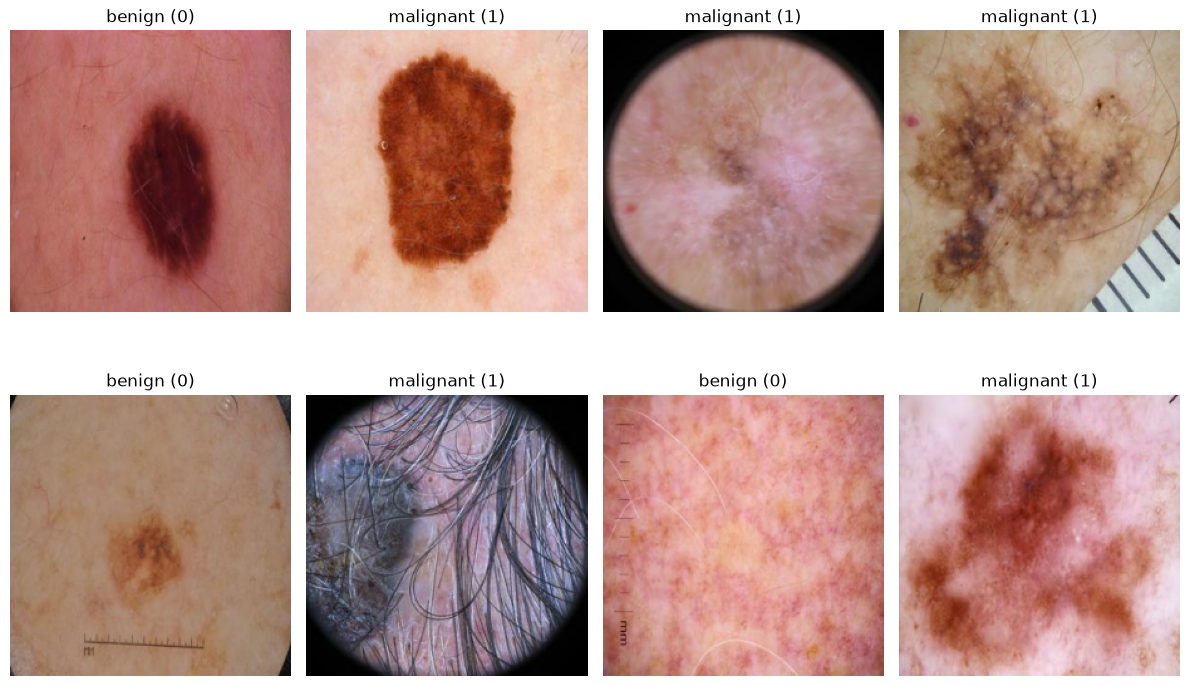

In [19]:
# Display sample images from training set
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = int(labels[i].numpy().squeeze())
        plt.title(f"{class_names[label_idx]} ({label_idx})")
        plt.axis("off")
plt.tight_layout()
plt.show()

In [20]:
# Dataset prefetching to optimize GPU/CPU throughput
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset prefetching completed!")

Dataset prefetching completed!


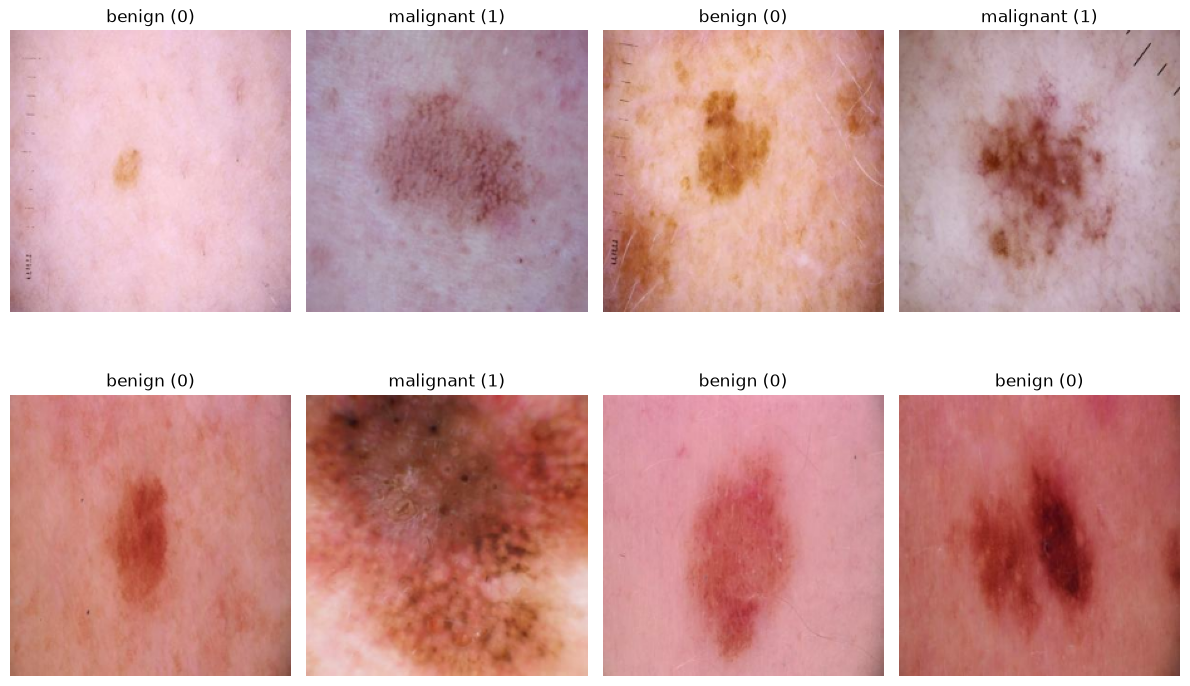

In [21]:
# Inspect one batch of images and labels
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy().astype("uint8"))
    label = int(labels[i].numpy().squeeze())
    ax.set_title(f"{class_names[label]} ({label})")
    ax.axis("off")
plt.tight_layout()
plt.show()

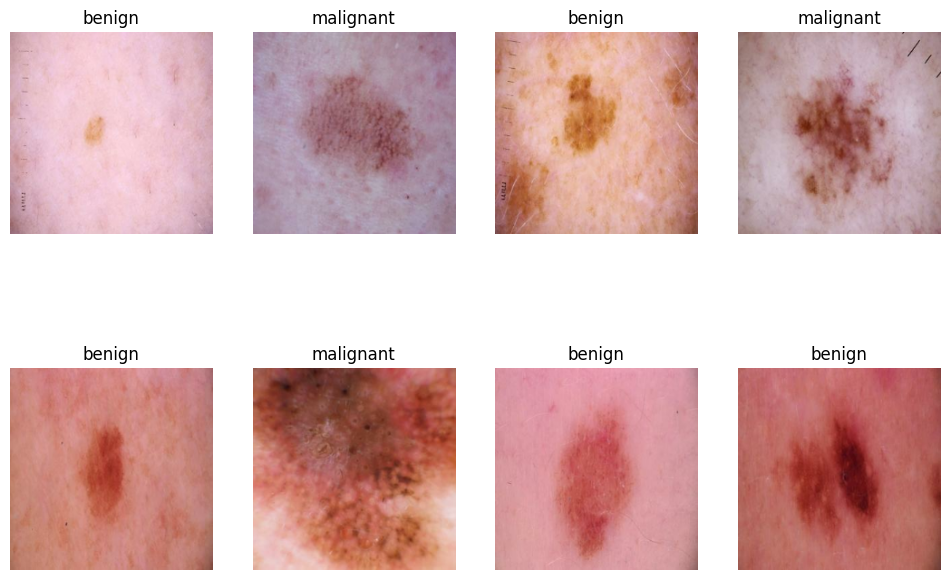

In [ ]:
# Summary of batch shapes
print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")

In [22]:
print("Class names:", class_names)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Class names: ['benign', 'malignant']
Training batches: 241
Validation batches: 61
Testing batches: 32


In [23]:
import tensorflow as tf

# Load pre-trained EfficientNetB0 backbone without top classifier
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze base model layers
base_model.trainable = False

# Build classification head
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs, name="Melanoma_Classifier_EfficientNetB0")

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)
print("Model successfully created and compiled!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Model successfully created and compiled!


In [24]:
# Display model architecture
model.summary()

print("\nAvailable GPUs:", tf.config.list_physical_devices('GPU'))

Model: "Melanoma_Classifier_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Available GPUs: []


In [25]:
# Configure training
print("Class mapping:", class_names)
assert class_names == ['benign', 'malignant'], "Unexpected class order. Check dataset folders."

# Use local file path instead of Colab's /content/ path
checkpoint_path = "best_skin_lesion_model.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("Training configuration ready!")

Class mapping: ['benign', 'malignant']
Training configuration ready!


In [26]:
# Model training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


241/241 ━━━━━━━━━━━━━━━━━━━━ 0s 855ms/step - accuracy: 0.8511 - auc: 0.9293 - loss: 0.3474 - precision: 0.8828 - recall: 0.7963
Epoch 1: val_loss improved from None to 0.26621, saving model to best_skin_lesion_model.keras

Epoch 1: finished saving model to best_skin_lesion_model.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.8511 - auc: 0.9293 - loss: 0.3474 - precision: 0.8828 - recall: 0.7963 - val_accuracy: 0.9027 - val_auc: 0.9597 - val_loss: 0.2662 - val_precision: 0.8897 - val_recall: 0.9064 - learning_rate: 0.0010
Epoch 2/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 0s 810ms/step - accuracy: 0.9010 - auc: 0.9602 - loss: 0.2544 - precision: 0.9101 - recall: 0.8813
Epoch 2: val_loss improved from 0.26621 to 0.23717, saving model to best_skin_lesion_model.keras

Epoch 2: finished saving model to best_skin_lesion_model.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 242s 1s/step - accuracy: 0.9010 - auc: 0.9602 - loss: 0.2544 - precision: 0.9101 - recall: 0.8813 - val_accuracy: 0.9115 - val_au

In [ ]:
# Plot training & validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy graph
axes[0].plot(history.history['accuracy'], label='Training Accuracy', lw=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', lw=2)
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(history.history['loss'], label='Training Loss', lw=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', lw=2)
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Epoch 1/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7903 - auc: 0.8731 - loss: 0.4312 - precision: 0.8170 - recall: 0.7078
Epoch 1: val_loss improved from None to 0.26196, saving model to /content/best_skin_lesion_model.keras

Epoch 1: finished saving model to /content/best_skin_lesion_model.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 1256s 5s/step - accuracy: 0.8533 - auc: 0.9330 - loss: 0.3420 - precision: 0.8793 - recall: 0.8058 - val_accuracy: 0.9016 - val_auc: 0.9605 - val_loss: 0.2620 - val_precision: 0.8946 - val_recall: 0.8976 - learning_rate: 0.0010
Epoch 2/10
240/241 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9005 - auc: 0.9580 - loss: 0.2629 - precision: 0.9125 - recall: 0.8753
Epoch 2: val_loss improved from 0.26196 to 0.23590, saving model to /content/best_skin_lesion_model.keras

Epoch 2: finished saving model to /content/best_skin_lesion_model.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 24s 101ms/step - accuracy: 0.9012 - auc: 0.9598 - loss: 0.2552 - precision: 0.9136 - 

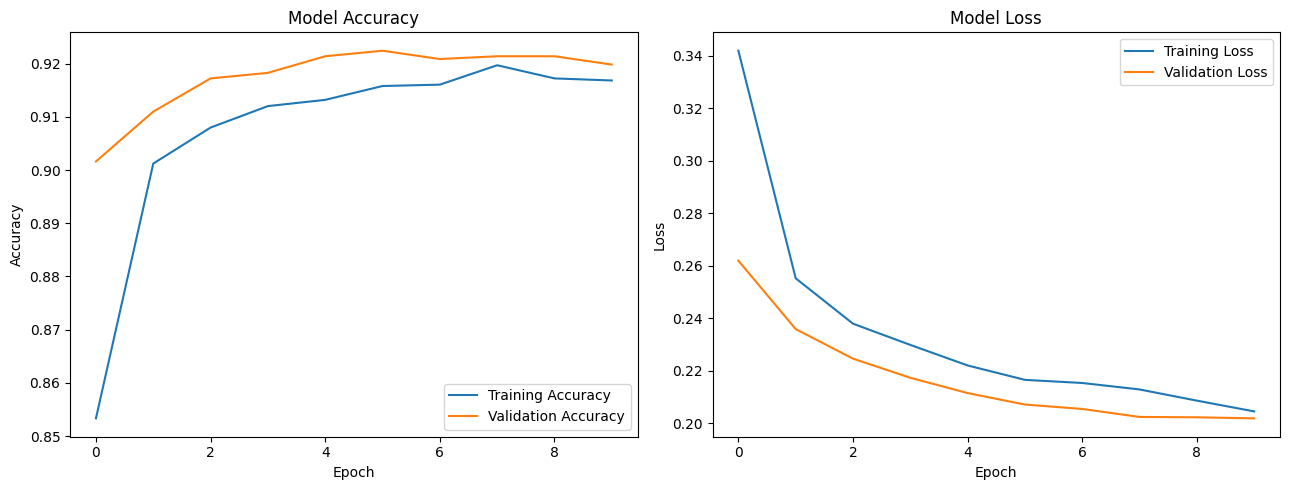

In [ ]:
# Evaluate model on the test dataset
test_results = model.evaluate(test_ds, return_dict=True)
print("\n--- TEST RESULTS ---")
for metric_name, val in test_results.items():
    print(f"Test {metric_name.capitalize()}: {val:.4f}")

In [ ]:
# Classification Report
import numpy as np
from sklearn.metrics import classification_report

# Extract actual labels as integers
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# Predict probabilities on test dataset
y_prob = model.predict(test_ds).ravel()

# Convert probabilities to binary classes (0 or 1)
y_pred = (y_prob >= 0.5).astype(int)

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 156s 5s/step - accuracy: 0.9080 - auc: 0.9699 - loss: 0.2116 - precision: 0.9250 - recall: 0.8880

 TEST RESULTS
Test Loss: 0.21159973740577698
Test Accuracy: 0.9079999923706055
Test AUC: 0.9698799848556519
Test Precision: 0.925000011920929
Test Recall: 0.8880000114440918


In [ ]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(cmap="Blues", values_format="d")
plt.title("Skin Lesion Classification - Confusion Matrix")
plt.grid(False)
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 363ms/step
              precision    recall  f1-score   support

      benign       0.89      0.93      0.91       500
   malignant       0.93      0.89      0.91       500

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



### Confusion Matrix Interpretation:
- **Benign (Class 0)**: Non-cancerous lesions accurately classified vs misdiagnosed.
- **Malignant (Class 1)**: Melanoma lesions correctly identified (True Positives) vs missed (False Negatives).


In [4]:
#roc and aoc calculatio
from sklearn.metrics import roc_curve,roc_auc_score
auc_score=roc_auc_score(y_true,y_prob)
fpr,tpr,_= roc_curve(y_true,y_prob)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC_AUC:",auc_score)

NameError: name 'y_true' is not defined

In [30]:
# Save final trained model locally
model_save_path = "skin_lesion_practice_model.keras"
model.save(model_save_path)
print(f"Model saved successfully to: {model_save_path}")

Model saved successfully to: skin_lesion_practice_model.keras


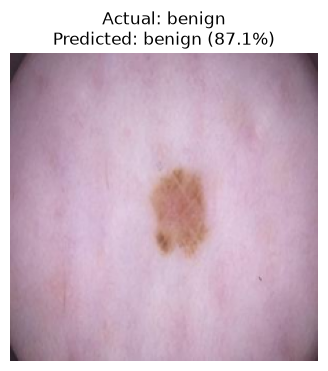

In [27]:
# Sample Single-Image Inference Test
for test_images, test_labels in test_ds.take(1):
    sample_img = test_images[0]
    actual_label = class_names[int(test_labels[0].numpy().squeeze())]

    # Model prediction
    img_batch = tf.expand_dims(sample_img, 0)
    prob = float(model.predict(img_batch, verbose=0)[0][0])
    pred_label = class_names[int(prob >= 0.5)]
    confidence = prob if prob >= 0.5 else 1.0 - prob

    plt.figure(figsize=(4, 4))
    plt.imshow(sample_img.numpy().astype("uint8"))
    plt.title(f"Actual: {actual_label}\nPredicted: {pred_label} ({confidence:.1%})")
    plt.axis("off")
    plt.show()
    break